# BMLL follow-on: daily fund ledger, validation and research extensions

Consumes full tables exported from `BMLL_Stage1_2_Corporate_Actions_WRDS_Bloomberg.ipynb`.
Runs on Colab or a local CPU. Keep this notebook, `research_pipeline.py`, and the first notebook together.
On Colab, upload the project files and data first, or change `PROJECT_DIR` to your project folder.

## What the previous run actually established
The saved run contains 17 quarterly snapshots (8,551 rows), a 503-security inception example,
and a WRDS corporate-action extraction for **15 securities**. The unscoped comparison reported
164 agreements, 35 conflicts, 8,298 Bloomberg-only and 2 WRDS-only events. All 8,499 rows remained
in the review queue; even agreement did not imply approval. Bloomberg contains 8,497 events,
including six without ex-dates and events outside the WRDS window.

These are observations from the saved run, not a claim that its truncated displays contain complete reusable data.

## Run order
1. In the first notebook's existing kernel, run the new **5L handoff** cell. It exports full in-memory tables.
2. Run sections 0–2 below. The default fetch mode refreshes the entire historical membership universe,
   daily raw prices, and calendar for the selected window through your WRDS account.
3. Review the generated event and scope decision CSVs in `data/stage2_review/`. Edit decisions and rationale,
   then rerun sections 2–4. No event is automatically approved.
4. Run optional flow, benchmark and execution sections when their inputs are supplied.

The baseline retains close-time decisions and next-session close proxy fills. Exact index-rebalance-close
execution needs independently valid advance announcements and is not implemented here.


## 0. Environment and configuration
Start with 2026-03-23 through 2026-06-30, which spans a quarterly rebalance and is within the saved WRDS release.
`INPUT_MODE="fetch_wrds"` queries your account when you execute section 1; `"cache"` reuses validated files.
The first notebook's globals are not shared across kernels. Run its handoff cell before continuing.


In [ ]:
%pip install "pandas>=2.0,<3" "numpy>=1.24,<3" "wrds>=3.2" "matplotlib>=3.7"

In [10]:
from pathlib import Path
import json
import hashlib
import sys
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path.cwd()  # change if the notebook was opened outside the project
sys.path.insert(0, str(PROJECT_DIR))
import importlib
import research_pipeline
importlib.reload(research_pipeline)  # pick up engine fixes in an existing kernel
from research_pipeline import (
    load_helpers, load_handoff, export_handoff, read_table, fetch_daily_prices,
    trading_calendar, scope_events, review_candidates, approved_events,
    prepare_exclusion_scenario, simulate, seeded_flows, benchmark_report, execution_comparison, validate_bmll_mapping,
)

SOURCE_NOTEBOOK = PROJECT_DIR / "BMLL_Stage1_2_Corporate_Actions_WRDS_Bloomberg.ipynb"
HANDOFF_DIR = PROJECT_DIR / "data/stage1_handoff"
INPUT_DIR = PROJECT_DIR / "data/stage2_inputs"
REVIEW_DIR = PROJECT_DIR / "data/stage2_review"
OUTPUT_DIR = PROJECT_DIR / "outputs/daily_fund"
BLOOMBERG_CSV = PROJECT_DIR / "data/BMLL_Bloomberg_Corporate_Actions.csv"
INPUT_MODE = "fetch_wrds"  # or "cache" after a successful fetch
START_DATE = "2026-03-23"
END_DATE = "2026-06-30"
STOCK_SCHEMA = "crsp_q_stock"
INITIAL_CASH = 10_000_000_000.0
CASH_BUFFER_BPS = 10.0
FEE_BPS = 0.0  # illustrative, not calibrated execution costs
BATCH_SIZE = 150
# Optional inputs; leave absent until you have the documented files.
BENCHMARK_CSV = PROJECT_DIR / "data/benchmark_returns.csv"
BMLL_MAPPING_CSV = PROJECT_DIR / "data/bmll_identifier_mapping.csv"
EXECUTION_CSV = PROJECT_DIR / "data/execution_observations.csv"
ACTUAL_FLOWS_CSV = PROJECT_DIR / "data/investor_flows.csv"
for folder in (INPUT_DIR, REVIEW_DIR, OUTPUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)
helpers = load_helpers(SOURCE_NOTEBOOK)  # definitions only; no upstream example is executed
print("Helper definitions loaded. CPU computations; WRDS connections occur only in section 1.")


Helper definitions loaded. CPU computations; WRDS connections occur only in section 1.


## 1. Handoff, full-universe coverage and raw daily prices
The upstream 15-name sample cannot support a 503-name daily portfolio. Fetch mode obtains the union
of membership records overlapping the window, plus every name in the selected quarterly snapshots.
It checks required table availability rather than silently substituting missing tables.

The 10-day extraction padding supports adjacent cumulative-factor checks. Replay events are then
restricted to the actual window. The calendar comes from the selected WRDS release, not assumed weekdays.
An absent session or quote is never filled with a stale price. The inception is all cash: this notebook
cannot resume an arbitrary mid-life portfolio with preexisting dividend entitlements.


In [11]:
manifest, upstream = load_handoff(HANDOFF_DIR)
quarterly_weights = upstream["weights"]
if not {"nominal_date", "reference_date", "date", "permno", "cap_weight_proxy"} <= set(quarterly_weights):
    raise ValueError("Handoff weights must be the quarterly panel from section 3b, not a single-date snapshot")
snapshots = quarterly_weights[quarterly_weights.date.between(START_DATE, END_DATE)].copy()
if snapshots.empty or snapshots.date.min() != pd.Timestamp(START_DATE):
    raise ValueError("START_DATE must be a decision snapshot present in the quarterly panel")
print("Upstream selected securities:", len(manifest.get("selected_permnos", [])))
print("Selected snapshots:", snapshots.date.nunique(), "rows:", len(snapshots))

if INPUT_MODE == "fetch_wrds":
    with helpers["wrds_session"]() as db:
        first_price, last_price = helpers["get_price_bounds"](db, f"{STOCK_SCHEMA}.dsf_v2")
        if pd.Timestamp(START_DATE) < first_price or pd.Timestamp(END_DATE) > last_price:
            raise ValueError(f"Selected release only covers {first_price.date()} through {last_price.date()}")
        member_schema = STOCK_SCHEMA.replace("_stock", "_indexes")
        members = db.raw_sql(
            f"SELECT DISTINCT permno FROM {member_schema}.dsp500list_v2 "
            "WHERE mbrstartdt <= %(end)s AND (mbrenddt IS NULL OR mbrenddt >= %(start)s)",
            params={"start": START_DATE, "end": END_DATE})
        universe = sorted(set(members.permno.dropna().astype(int)) | set(snapshots.permno.astype(int)))
        extract_start = str((pd.Timestamp(START_DATE) - pd.Timedelta(days=10)).date())
        report, discovered = helpers["discover_ca_tables"](db, schemas=[STOCK_SCHEMA])
        available = report.groupby("table").available.any()
        if not all(bool(available.get(t, False)) for t in helpers["CA_TABLE_NAMES"]):
            display(report)
            raise ValueError("Missing required WRDS table; resolve the coverage gap before replay")
        bundle = {table: helpers["fetch_wrds_ca_table"](db, discovered, table, universe, extract_start, END_DATE)
                  for table in helpers["CA_TABLE_NAMES"]}
        prices = fetch_daily_prices(db, universe, START_DATE, END_DATE, STOCK_SCHEMA, BATCH_SIZE)
        calendar_frame = trading_calendar(db, START_DATE, END_DATE, STOCK_SCHEMA)
    raw_bloomberg = pd.read_csv(BLOOMBERG_CSV, dtype={"cusip": "string", "ticker": "string"})
    mapped_bloomberg = helpers["normalize_bloomberg_export"](raw_bloomberg, bundle["stksecurityinfohist"])
    wrds_events = helpers["normalize_wrds_distributions"](bundle["stkdistributions"])
    delists = helpers["normalize_wrds_delists"](bundle["stkdelists"])
    refreshed = dict(weights=quarterly_weights, wrds_corporate_actions=wrds_events,
        wrds_delist_events=delists, wrds_adj_factors=bundle["stkdlycumulativeadjfactor"],
        wrds_id_history=bundle["stksecurityinfohist"], bloomberg_corporate_actions=mapped_bloomberg,
        unified_corporate_actions=upstream["unified_corporate_actions"], wrds_table_report=report,
        wrds_ca_bundle=bundle, selected_permnos=universe, CA_START_DATE=extract_start, CA_END_DATE=END_DATE)
    export_handoff(refreshed, INPUT_DIR)
    prices.to_csv(INPUT_DIR / "daily_prices.csv", index=False)
    calendar_frame.to_csv(INPUT_DIR / "calendar.csv", index=False)
    cache_meta = {"start": START_DATE, "end": END_DATE, "schema": STOCK_SCHEMA, "universe": universe,
        "bloomberg_sha256": hashlib.sha256(BLOOMBERG_CSV.read_bytes()).hexdigest(),
        "extra_sha256": {name: hashlib.sha256((INPUT_DIR / name).read_bytes()).hexdigest()
                         for name in ["daily_prices.csv", "calendar.csv"]}}
    (INPUT_DIR / "coverage.json").write_text(json.dumps(cache_meta, indent=2))
elif INPUT_MODE != "cache":
    raise ValueError("INPUT_MODE must be fetch_wrds or cache")

coverage = json.loads((INPUT_DIR / "coverage.json").read_text())
if (coverage["start"], coverage["end"], coverage["schema"]) != (START_DATE, END_DATE, STOCK_SCHEMA):
    raise ValueError("Cache dates/schema differ; fetch again")
if hashlib.sha256(BLOOMBERG_CSV.read_bytes()).hexdigest() != coverage["bloomberg_sha256"]:
    raise ValueError("Bloomberg CSV changed; fetch/remap again")
for name, digest in coverage["extra_sha256"].items():
    if hashlib.sha256((INPUT_DIR / name).read_bytes()).hexdigest() != digest:
        raise ValueError(f"Changed input: {name}; refresh cache")
_, inputs = load_handoff(INPUT_DIR)
universe = coverage["universe"]
prices = read_table(INPUT_DIR / "daily_prices.csv")
calendar = read_table(INPUT_DIR / "calendar.csv").date
if calendar.empty or calendar.min() != pd.Timestamp(START_DATE) or calendar.max() > pd.Timestamp(END_DATE):
    raise ValueError("Calendar does not cover configured inception")
print("Historical securities:", len(universe), "price rows:", len(prices), "sessions:", len(calendar))
display(inputs["wrds_table_report"])


Upstream selected securities: 15
Selected snapshots: 2 rows: 1006
Connecting to WRDS...
✓ WRDS login environment configured.
Loading library list...
Done
Approximately 1122339 rows in crsp_q_stock.stkdistributions.
Approximately 28622 rows in crsp_q_stock.stkdelists.
Approximately 111555760 rows in crsp_q_stock.stkdlycumulativeadjfactor.
Approximately 193968 rows in crsp_q_stock.stksecurityinfohist.


/Users/tanishpatel01/Desktop/Simulated-Investment-Manager/BMLL_Stage1_2_Corporate_Actions_WRDS_Bloomberg.ipynb:cell-40:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
/Users/tanishpatel01/Desktop/Simulated-Investment-Manager/BMLL_Stage1_2_Corporate_Actions_WRDS_Bloomberg.ipynb:cell-40:39: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.


✓ WRDS database connection closed.
Historical securities: 509 price rows: 34912 sessions: 69


,schema,table,available,missing_required,note
0,crsp_q_stock,stkdistributions,True,NaN,19 columns
1,crsp_q_stock,stkdelists,True,NaN,19 columns
2,crsp_q_stock,stkdlycumulativeadjfactor,True,NaN,5 columns
3,crsp_q_stock,stksecurityinfohist,True,NaN,36 columns


## 2. Comparable reconciliation and documented review
Both sources are restricted to the same dates and historical universe. Bloomberg records with unknown
identities or missing dates go to a separate scope quarantine. Known out-of-universe/out-of-window
records are excluded by the declared scope; unknown records require an explicit documented exclusion
or corrected source data and a refresh. They are not silently discarded.

`event_decisions.csv`: for every candidate choose `APPROVE` or `EXCLUDE`, select one of that row's
source event IDs, and write `rationale`. Agreement is evidence to review, not automatic approval.
Only reviewed ordinary splits and USD cash dividends can be applied. A pure share split has no cash currency requirement. Review currency-check notes,
CINS mappings and amount/date conflicts. Complex events must be implemented before claiming a complete
history; excluding a real held-security event makes the run a limited research scenario.

`scope_decisions.csv`: use `EXCLUDE` with a rationale only when you can establish that the record is
outside the experiment. To include an unresolved record, correct its identity/date in the source and
refresh section 1. Generated templates are not overwritten. Stale decisions must be regenerated or
updated deliberately; the replay will reject them.


In [5]:
wrds_parts = [inputs[name] for name in ["wrds_corporate_actions", "wrds_delist_events"] if not inputs[name].empty]
wrds_all = pd.concat(wrds_parts, ignore_index=True) if wrds_parts else inputs["wrds_corporate_actions"].copy()
bloomberg_all = inputs["bloomberg_corporate_actions"]
wrds_scoped, wrds_unknown = scope_events(wrds_all, universe, START_DATE, END_DATE)
bbg_scoped, bbg_unknown = scope_events(bloomberg_all, universe, START_DATE, END_DATE)
quarantine = pd.concat([wrds_unknown, bbg_unknown], ignore_index=True)
sources = pd.concat([wrds_scoped, bbg_scoped], ignore_index=True)
unified = helpers["reconcile_corporate_actions"](wrds_scoped, bbg_scoped)
candidates = review_candidates(unified, sources)
factor_checks = helpers["check_split_factors"](wrds_scoped, inputs["wrds_adj_factors"])
# Mismatched/missing factor evidence remains visible to the reviewer.
factor_checks.to_csv(REVIEW_DIR / "split_factor_checks.csv", index=False)
candidates.to_csv(REVIEW_DIR / "event_candidates.csv", index=False)
quarantine.to_csv(REVIEW_DIR / "scope_quarantine.csv", index=False)

def create_template(path, frame):
    if not path.exists():
        frame.to_csv(path, index=False)

create_template(REVIEW_DIR / "event_decisions.csv", candidates)
scope_template = quarantine.copy()
scope_template["decision"] = "PENDING"
scope_template["rationale"] = ""
create_template(REVIEW_DIR / "scope_decisions.csv", scope_template)
display(unified.match_status.value_counts().rename("events"))
print("Scope quarantine:", len(quarantine), "| Decisions folder:", REVIEW_DIR)
display(candidates.head(10))
display(factor_checks)


match_status
MATCHED_AGREE       443
MATCHED_CONFLICT     12
WRDS_ONLY             8
BLOOMBERG_ONLY        3
Name: events, dtype: int64

Scope quarantine: 32 | Decisions folder: /Users/tanishpatel01/Desktop/Simulated-Investment-Manager/data/stage2_review


,match_status,wrds_event_id,bloomberg_event_id,permno,event_type,ex_date,wrds_cash_per_share,bloomberg_cash_per_share,wrds_split_ratio,bloomberg_split_ratio,wrds_pay_date,bloomberg_pay_date,review_reason,requires_review,review_status,review_key,decision,chosen_source_event_id,rationale
0,MATCHED_CONFLICT,CRSP:DIST:84769:2026-03-23:1,BBG:032095101:CASH_DIVIDEND:2026-03-23,84769,CASH_DIVIDEND,2026-03-23,0.2500,0.1250,NaN,NaN,2026-04-14,2026-04-14,cash_amount_conflict,True,PENDING,57ec461761daedb89cc3d5ef,PENDING,CRSP:DIST:84769:2026-03-23:1,
1,MATCHED_AGREE,CRSP:DIST:93002:2026-03-23:1,BBG:11135F101:CASH_DIVIDEND:2026-03-23,93002,CASH_DIVIDEND,2026-03-23,0.6500,0.6500,NaN,NaN,2026-03-31,2026-03-31,,False,PENDING,c60219f7227d7d91874912a7,PENDING,CRSP:DIST:93002:2026-03-23:1,
2,MATCHED_AGREE,CRSP:DIST:15707:2026-03-24:1,BBG:42824C109:CASH_DIVIDEND:2026-03-24,15707,CASH_DIVIDEND,2026-03-24,0.1425,0.1425,NaN,NaN,2026-04-23,2026-04-23,,False,PENDING,744f77a858e477aaa8680115,PENDING,CRSP:DIST:15707:2026-03-24:1,
3,MATCHED_AGREE,CRSP:DIST:23473:2026-03-24:1,BBG:172062101:CASH_DIVIDEND:2026-03-24,23473,CASH_DIVIDEND,2026-03-24,0.9400,0.9400,NaN,NaN,2026-04-15,2026-04-15,,False,PENDING,a9c4487b2231d98f485b2c50,PENDING,CRSP:DIST:23473:2026-03-24:1,
4,MATCHED_AGREE,CRSP:DIST:85914:2026-03-24:1,BBG:086516101:CASH_DIVIDEND:2026-03-24,85914,CASH_DIVIDEND,2026-03-24,0.9600,0.9600,NaN,NaN,2026-04-14,2026-04-14,,False,PENDING,6f3c58354f74ca60c280d9da,PENDING,CRSP:DIST:85914:2026-03-24:1,
5,MATCHED_AGREE,CRSP:DIST:12084:2026-03-25:1,BBG:N6596X109:CASH_DIVIDEND:2026-03-25,12084,CASH_DIVIDEND,2026-03-25,1.0140,1.0140,NaN,NaN,2026-04-09,2026-04-09,,False,PENDING,00e15b26eeff541cb4ee38dc,PENDING,CRSP:DIST:12084:2026-03-25:1,
6,MATCHED_AGREE,CRSP:DIST:13901:2026-03-25:1,BBG:02209S103:CASH_DIVIDEND:2026-03-25,13901,CASH_DIVIDEND,2026-03-25,1.0600,1.0600,NaN,NaN,2026-04-30,2026-04-30,,False,PENDING,31e745354bc7a42c39417999,PENDING,CRSP:DIST:13901:2026-03-25:1,
7,MATCHED_AGREE,CRSP:DIST:89641:2026-03-25:1,BBG:G7997R103:CASH_DIVIDEND:2026-03-25,89641,CASH_DIVIDEND,2026-03-25,0.7400,0.7400,NaN,NaN,2026-04-08,2026-04-08,,False,PENDING,062a119b1549fa7504feddc3,PENDING,CRSP:DIST:89641:2026-03-25:1,
8,MATCHED_AGREE,CRSP:DIST:16581:2026-03-26:1,BBG:46187W107:CASH_DIVIDEND:2026-03-26,16581,CASH_DIVIDEND,2026-03-26,0.3000,0.3000,NaN,NaN,2026-04-17,2026-04-17,,False,PENDING,28e86642802337201a0510de,PENDING,CRSP:DIST:16581:2026-03-26:1,
9,MATCHED_AGREE,CRSP:DIST:17942:2026-03-27:1,BBG:49271V100:CASH_DIVIDEND:2026-03-27,17942,CASH_DIVIDEND,2026-03-27,0.2300,0.2300,NaN,NaN,2026-04-10,2026-04-10,,False,PENDING,590fcf2670c25858fd54b1ab,PENDING,CRSP:DIST:17942:2026-03-27:1,


,source_event_id,permno,ex_date,reported_split_ratio,implied_split_ratio,status
0,CRSP:DIST:10145:2026-06-29:2,10145,2026-06-29,0.500000,0.500000,AGREE
1,CRSP:DIST:16655:2026-05-08:1,16655,2026-05-08,5.000000,5.000000,AGREE
2,CRSP:DIST:16851:2026-06-24:1,16851,2026-06-24,0.333333,0.333333,AGREE
3,CRSP:DIST:46886:2026-06-12:1,46886,2026-06-12,10.000000,10.000000,AGREE
4,CRSP:DIST:86783:2026-04-06:1,86783,2026-04-06,25.000000,25.000000,AGREE


In [12]:
# READY is computed by validation; it is not a live-mode switch.
READY = False
approved = None
approval_audit = pd.DataFrame()
try:
    scope_decisions = pd.read_csv(REVIEW_DIR / "scope_decisions.csv")
    if scope_decisions.source_event_id.duplicated().any() or set(scope_decisions.source_event_id) != set(quarantine.source_event_id):
        raise ValueError("Scope decisions are stale, duplicated or incomplete")
    if not scope_decisions.empty and (
        not scope_decisions.decision.eq("EXCLUDE").all()
        or scope_decisions.rationale.fillna("").str.strip().eq("").any()):
        raise ValueError("Review unknown identity/date records in scope_decisions.csv")
    decisions = pd.read_csv(REVIEW_DIR / "event_decisions.csv")
    approved, approval_audit = approved_events(candidates, decisions, sources)
    approved.to_csv(REVIEW_DIR / "approved_events.csv", index=False)
    approval_audit.to_csv(REVIEW_DIR / "approval_audit.csv", index=False)
    READY = True
    print("Approved events:", len(approved), "| Explicit event exclusions:", approval_audit.decision.eq("EXCLUDE").sum())
    print("Scope exclusions:", len(scope_decisions), "| Review exclusions before interpreting results.")
except ValueError as exc:
    READY = False
    approved = None
    print("Replay awaits review:", exc)
    print("Edit decision CSVs, then rerun this cell and downstream sections.")


Approved events: 453 | Explicit event exclusions: 13
Scope exclusions: 32 | Review exclusions before interpreting results.


## 3. Persistent daily ledger and quarterly rebalance integration
Start from cash on the first selected decision date. Apply splits to carried positions and pending orders;
accrue dividends on ex-date; pay on payment dates, including weekends and after sale. On session closes,
mark with raw prices, apply external cash flows at pre-flow unit NAV, and execute the previous session's
orders. Generate new orders only after that close using the observed snapshot. Sells precede buys;
insufficient cash scales buy quantities; residual unfilled orders expire at that close.

The cash buffer is a target, not a guarantee after next-session price changes. Unpaid receivables are
included in NAV but excluded from the investable target budget. A split does not itself trigger a rebalance.
The engine stops for missing prices, unreviewed/unsupported actions, fractional split shares and same-day
split/dividend sequencing. No delisting return, merger payoff or successor shares are invented.

### Restricted portfolio after event exclusions
The default `EXCLUDED_EVENT_POLICY="exclude_securities"` omits every security with an explicitly excluded action from the entire experiment, then renormalizes the remaining snapshot weights. This prevents retaining delisted shares whose merger settlement was omitted. Reverse-split securities are also omitted by default because actual fractional-share settlement is unavailable. The omitted names and original weights are exported, and source prices remain unchanged. This is a restricted portfolio experiment, not full-index performance. Set `keep_securities` only after implementing the omitted accounting.


In [13]:
results = None
replay_snapshots, replay_events = snapshots, approved
# Keep the omission policy explicit: a subset portfolio, not a complete S&P 500 replay.
EXCLUDED_EVENT_POLICY = "exclude_securities"  # "keep_securities" retains strict failure on missing accounting
EXCLUDE_REVERSE_SPLIT_SECURITIES = True  # no invented fractional cash-in-lieu
if READY:
    if EXCLUDED_EVENT_POLICY == "exclude_securities":
        replay_snapshots, replay_events, excluded_securities = prepare_exclusion_scenario(
            snapshots, approved, approval_audit,
            exclude_reverse_splits=EXCLUDE_REVERSE_SPLIT_SECURITIES)
        excluded_securities.to_csv(OUTPUT_DIR / "excluded_security_snapshots.csv", index=False)
        print("Restricted portfolio: omitted securities from inception; retained weights renormalized.")
        display(excluded_securities[[col for col in ["date", "permno", "ticker", "cap_weight_proxy", "exclusion_reason"]
                                    if col in excluded_securities]])
    elif EXCLUDED_EVENT_POLICY != "keep_securities":
        raise ValueError("Unknown EXCLUDED_EVENT_POLICY")
    results = simulate(replay_snapshots, prices, calendar, replay_events, START_DATE, END_DATE,
        initial_cash=INITIAL_CASH, cash_buffer_bps=CASH_BUFFER_BPS, fee_bps=FEE_BPS)
    for name in ["daily_nav", "daily_holdings", "fills", "orders", "action_journal"]:
        results[name].to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
    display(results["daily_nav"].tail())
    display(results["fills"].head())
    print("Unpaid ending receivables:", results["ending_receivables"])
    print("Orders pending beyond experiment end:", results["pending_orders"])
else:
    print("Complete section 2 reviews before running the historical ledger.")


Restricted portfolio: omitted securities from inception; retained weights renormalized.


,date,permno,ticker,cap_weight_proxy,exclusion_reason
7619,2026-03-23,10145,HON,0.002414,excluded_corporate_action;reverse_split_fracti...
7673,2026-03-23,60628,FDX,0.001425,excluded_corporate_action
7874,2026-03-23,76082,CTRA,0.000437,excluded_corporate_action
7884,2026-03-23,17743,WRB,0.000424,excluded_corporate_action
7944,2026-03-23,16851,DD,0.000308,reverse_split_fractional_settlement_not_implem...
7955,2026-03-23,76095,HOLX,0.000288,excluded_corporate_action
7973,2026-03-23,13103,APTV,0.000257,excluded_corporate_action
7987,2026-03-23,46703,HST,0.000224,excluded_corporate_action
8128,2026-06-22,10145,HON,0.002164,excluded_corporate_action;reverse_split_fracti...
8193,2026-06-22,60628,FDX,0.001174,excluded_corporate_action


,date,cash,equity_value,receivables,nav,external_flow,fund_units,unit_nav,fees,fund_return
64,2026-06-24,1.667993e+07,1.120888e+10,8.323546e+06,1.123388e+10,0.0,100000000.0,112.338839,0.0,-0.001268
65,2026-06-25,1.727290e+07,1.120368e+10,8.234880e+06,1.122919e+10,0.0,100000000.0,112.291895,0.0,-0.000418
66,2026-06-26,1.905829e+07,1.119998e+10,6.734443e+06,1.122578e+10,0.0,100000000.0,112.257775,0.0,-0.000304
67,2026-06-29,1.971395e+07,1.133628e+10,6.153211e+06,1.136215e+10,0.0,100000000.0,113.621461,0.0,0.012148
68,2026-06-30,2.201270e+07,1.142203e+10,4.927844e+06,1.144897e+10,0.0,100000000.0,114.489668,0.0,0.007641


,decision_date,execution_date,permno,signed_requested,signed_filled,unfilled_quantity,execution_price,decision_price,fee,executed_reference_drift
0,2026-03-23,2026-03-24,10104,492065,492065,0,147.09,154.34,0.0,-3567471.25
1,2026-03-23,2026-03-24,10107,1271321,1271321,0,372.74,383.00,0.0,-13043753.46
2,2026-03-23,2026-03-24,10138,37255,37255,0,88.80,87.98,0.0,30549.10
3,2026-03-23,2026-03-24,10516,82385,82385,0,71.44,67.99,0.0,284228.25
4,2026-03-23,2026-03-24,10696,91415,91415,0,56.34,57.71,0.0,-125238.55


Unpaid ending receivables: {'CRSP:DIST:27887:2026-05-29:1': (Timestamp('2026-07-01 00:00:00'), 880.84, 27887), 'CRSP:DIST:35044:2026-06-01:1': (Timestamp('2026-07-01 00:00:00'), 39177.07, 35044), 'CRSP:DIST:57665:2026-06-01:1': (Timestamp('2026-07-01 00:00:00'), 83636.72, 57665), 'CRSP:DIST:79323:2026-06-01:1': (Timestamp('2026-07-01 00:00:00'), 47988.72, 79323), 'CRSP:DIST:81061:2026-06-01:1': (Timestamp('2026-07-01 00:00:00'), 17195.399999999998, 81061), 'CRSP:DIST:82775:2026-06-01:1': (Timestamp('2026-07-02 00:00:00'), 28337.399999999998, 82775), 'CRSP:DIST:14277:2026-06-03:1': (Timestamp('2026-07-09 00:00:00'), 75523.245, 14277), 'CRSP:DIST:79145:2026-06-03:1': (Timestamp('2026-07-02 00:00:00'), 69474.0, 79145), 'CRSP:DIST:17750:2026-06-05:1': (Timestamp('2026-07-02 00:00:00'), 72739.84, 17750), 'CRSP:DIST:46674:2026-06-05:1': (Timestamp('2026-07-02 00:00:00'), 25033.5625, 46674), 'CRSP:DIST:58246:2026-06-05:1': (Timestamp('2026-07-01 00:00:00'), 25382.4, 58246), 'CRSP:DIST:85459:2

## 4. Quarter validation and remaining complex-action work
Every simulated session checks NAV conservation through trades and fees. The automated tests independently
exercise a full synthetic quarter, weekend dividend payments, dividends paid after sale, split-adjusted
pending orders, no split-driven synthetic trades, cash shortages and missing-price stops.

A passing synthetic quarter is not a validated real quarter. For real sign-off, review the exported action
journal against source events, reconcile share/cash changes and receivables, investigate price flags and
check all exclusions. Record the data version and approval decisions with the result.

Not implemented: general merger/spin-off/rights/delisting accounting, special distributions, fractional-share
cash-in-lieu, same-day split/dividend sequencing, FX, restart from an intermediate portfolio, and exact
index-rebalance-close methodology. These remain explicit blockers for affected histories, rather than
being converted into ordinary split/dividend events. Review-key approvals resolve source disagreements
by selecting an existing record; corrections require correcting/refetching the upstream source.


sessions                                            69
first_session                      2026-03-23 00:00:00
last_session                       2026-06-30 00:00:00
snapshot_decisions                                   2
ending_nav                          11448966784.474758
ending_cash                            22012696.714758
ending_receivables                          4927844.04
minimum_cash                           16655551.230438
fees                                               0.0
unitized_total_return                         0.144897
restricted_portfolio                              True
explicit_event_exclusions                           13
scope_exclusions                                    32
real_quarter_manually_validated                  False
dtype: object

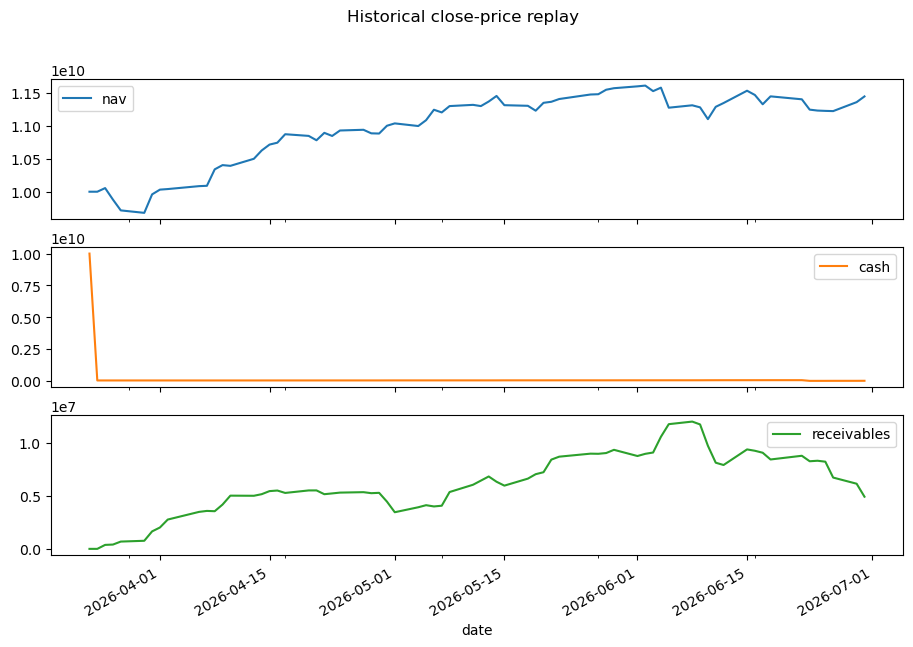

In [14]:
if results is not None:
    nav = results["daily_nav"]
    positions = results["daily_holdings"]
    summary = pd.Series({
        "sessions": len(nav), "first_session": nav.date.min(), "last_session": nav.date.max(),
        "snapshot_decisions": snapshots.date.nunique(), "ending_nav": nav.iloc[-1].nav,
        "ending_cash": nav.iloc[-1].cash, "ending_receivables": nav.iloc[-1].receivables,
        "minimum_cash": nav.cash.min(), "fees": nav.fees.sum(),
        "unitized_total_return": (1 + nav.fund_return).prod() - 1,
        "restricted_portfolio": EXCLUDED_EVENT_POLICY == "exclude_securities",
        "explicit_event_exclusions": int(approval_audit.decision.eq("EXCLUDE").sum()),
        "scope_exclusions": len(scope_decisions), "real_quarter_manually_validated": False,
    })
    display(summary)
    nav.set_index("date")[["nav", "cash", "receivables"]].plot(subplots=True, figsize=(11, 7), title="Historical close-price replay")
    summary.to_csv(OUTPUT_DIR / "validation_summary.csv", header=["value"])
    # Provenance references hashes of source files; no credentials are exported.
    run_provenance = {"start": START_DATE, "end": END_DATE, "aum": INITIAL_CASH,
        "cash_buffer_bps": CASH_BUFFER_BPS, "fee_bps": FEE_BPS,
        "files": {str(p.relative_to(PROJECT_DIR)): hashlib.sha256(p.read_bytes()).hexdigest()
                  for p in [INPUT_DIR / "manifest.json", INPUT_DIR / "coverage.json",
                            REVIEW_DIR / "event_decisions.csv", REVIEW_DIR / "scope_decisions.csv",
                            PROJECT_DIR / "research_pipeline.py", SOURCE_NOTEBOOK]}}
    (OUTPUT_DIR / "run_provenance.json").write_text(json.dumps(run_provenance, indent=2))


## 5. Investor flows and cash-buffer scenarios
Optional `data/investor_flows.csv`: `date,amount`, one USD net flow per session, positive for subscriptions.
Flows are issued/redeemed at current close pre-flow unit NAV, so deposits cannot masquerade as returns.
A redemption exceeding available cash stops; advance liquidation/notice policies remain to be designed.

The optional Monte Carlo below generates reproducible exogenous dollar flows and compares two target
cash buffers. It is a sensitivity experiment, not a calibrated investor model. Flow-driven rebalancing
uses the latest already-observed target weights, today's decision prices and the next session's fill proxy.


In [15]:
RUN_FLOW_SCENARIOS = False  # optional experiment, independent of live-data loading
N_SCENARIOS = 10
FLOW_SEED = 42
FLOW_SIGMA_BPS = 0.5
FLOW_BUFFER_BPS = [10., 50.]
if READY and ACTUAL_FLOWS_CSV.exists():
    flow_results = simulate(replay_snapshots, prices, calendar, replay_events, START_DATE, END_DATE,
        initial_cash=INITIAL_CASH, cash_buffer_bps=CASH_BUFFER_BPS, fee_bps=FEE_BPS,
        flows=read_table(ACTUAL_FLOWS_CSV), rebalance_on_flow=True)
    flow_results["daily_nav"].to_csv(OUTPUT_DIR / "actual_flows_nav.csv", index=False)
    display(flow_results["daily_nav"].tail())
if READY and RUN_FLOW_SCENARIOS:
    scenario_rows = []
    for i in range(N_SCENARIOS):
        flows = seeded_flows(calendar, INITIAL_CASH, FLOW_SIGMA_BPS, FLOW_SEED + i)
        for buffer in FLOW_BUFFER_BPS:
            try:
                replay = simulate(replay_snapshots, prices, calendar, replay_events, START_DATE, END_DATE,
                    initial_cash=INITIAL_CASH, cash_buffer_bps=buffer, fee_bps=FEE_BPS,
                    flows=flows, rebalance_on_flow=True)
                n = replay["daily_nav"]
                scenario_rows.append(dict(scenario=i, buffer_bps=buffer, status="COMPLETED",
                    total_return=(1 + n.fund_return).prod()-1, minimum_cash=n.cash.min()))
            except ValueError as exc:
                scenario_rows.append(dict(scenario=i, buffer_bps=buffer, status=str(exc)))
    scenario_report = pd.DataFrame(scenario_rows)
    display(scenario_report)
    scenario_report.to_csv(OUTPUT_DIR / "flow_scenarios.csv", index=False)
else:
    print("Flow scenarios are optional; the baseline has no investor flows.")


Flow scenarios are optional; the baseline has no investor flows.


## 6. Independent benchmark, BMLL mapping and execution analysis
### Benchmark
Supply `data/benchmark_returns.csv` with `date,benchmark_return` in decimal daily total returns, including
START_DATE's close-to-close return. Use an independently sourced USD total-return index and document its
provider, index variant and fees in your research record. The baseline is cash during its inception decision
session; that day's benchmark return is included intentionally. The report computes compounded returns
and annualized daily active-return standard deviation (252 sessions). CRSP cap-weight proxies remain
conceptually different from official float-adjusted index weights. No benchmark is fabricated or downloaded.

### BMLL map
Supply `data/bmll_identifier_mapping.csv`: `permno,bmll_id,valid_from,valid_to` (inclusive effective dates;
blank valid_to means open ended). The validator requires exactly one mapping for every requested daily
holding. This validates provided IDs; it cannot establish vendor coverage, venue, L2/L3 availability or rights.

### Execution / TCA
Supply `data/execution_observations.csv` with one aggregated row per actual order:
`order_id,side,quantity,filled_quantity,average_fill_price,arrival_price,terminal_price,fees,vwap,twap,auction_price`.
BUY/SELL, quantities in shares, prices in USD, fees in dollars. Unfilled orders may omit average_fill_price.
All references must use the same share basis after any corporate actions. Document the decision timestamp,
terminal horizon and eligible trading interval in your data preparation. The calculation includes executed
cost, unfilled opportunity cost and fees; missing VWAP/TWAP/auction references remain unavailable.

These are offline input interfaces and calculations, not an implemented BMLL connector or calibrated
auction/VWAP/TWAP execution strategy. Auction-volume participation, partial-fill generation, queue position,
market impact and timestamp-level no-look-ahead validation still need vendor data and model development.
The close-price replay's drift is never presented as actual implementation shortfall.


In [16]:
if results is not None and BENCHMARK_CSV.exists():
    benchmark_daily, benchmark_summary = benchmark_report(results["daily_nav"], read_table(BENCHMARK_CSV))
    display(pd.Series(benchmark_summary))
    benchmark_daily.to_csv(OUTPUT_DIR / "benchmark_comparison.csv", index=False)
else:
    print("Benchmark comparison awaits a ledger and independent benchmark_returns.csv.")
if results is not None and BMLL_MAPPING_CSV.exists() and not results["daily_holdings"].empty:
    mapping = pd.read_csv(BMLL_MAPPING_CSV, dtype={"bmll_id": "string"})
    mapped_holdings = validate_bmll_mapping(mapping, results["daily_holdings"])
    mapped_holdings.to_csv(OUTPUT_DIR / "validated_bmll_mapping.csv", index=False)
    print("Dated BMLL map validated for carried holdings; validate order-only names separately before routing.")
else:
    print("BMLL mapping awaits a ledger and bmll_identifier_mapping.csv.")
if EXECUTION_CSV.exists():
    execution_report = execution_comparison(pd.read_csv(EXECUTION_CSV))
    display(execution_report)
    execution_report.to_csv(OUTPUT_DIR / "execution_tca.csv", index=False)
else:
    print("Actual execution analysis awaits execution_observations.csv.")


Benchmark comparison awaits a ledger and independent benchmark_returns.csv.
BMLL mapping awaits a ledger and bmll_identifier_mapping.csv.
Actual execution analysis awaits execution_observations.csv.


## Completion checklist
- [ ] Full scoped source extraction and identifier/date coverage reviewed.
- [ ] All approvals, exclusions, currency checks and split-factor evidence reviewed.
- [ ] Real quarter's daily positions/cash/receivables/NAV independently reconciled.
- [ ] All complex actions affecting held securities implemented rather than excluded.
- [ ] Independent benchmark sourced and definition documented.
- [ ] Flow/redemption policy agreed and sensitivity experiments interpreted.
- [ ] Dated BMLL identifiers, price/volume coverage and timestamp alignment validated.
- [ ] Realistic execution strategies and full order-level TCA validated on actual data.

Implemented here: file handoff, scoped review workflow, ordinary-action daily accounting, quarterly
close-proxy replay, unitized flow sensitivity, supplied-benchmark metrics, mapping validation and supplied-order
TCA calculations. Missing external inputs and unresolved economic cases remain visible; a successful
notebook execution alone does not complete these research sign-offs.
